In [2]:
import os
import sys
import glob
import time
import json
import zipfile
import warnings
import collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve, r2_score
)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")

In [5]:
class Config:
    SEED = 42
    
    # Sequence & Time-Series Config
    SEQ_LENGTH = 168 # 7 days * 24 hours
    PREDICT_AHEAD = 24 # Predict risk for the next 24 hours
    
    TUNING_EPOCHS = 5      
    MAX_EPOCHS = 50       
    PATIENCE = 7           
    BATCH_SIZE = 256       
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    MAX_GRAD_NORM = 1.0
    
    # Device Configuration
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    MIXED_PRECISION = torch.cuda.is_available()
    
    # Hyperparameter Grid for Tuning
    HP_GRID = [
        {"hidden_size": 64, "num_layers": 2, "dropout": 0.2},
        {"hidden_size": 128, "num_layers": 2, "dropout": 0.3},
        {"hidden_size": 128, "num_layers": 3, "dropout": 0.4}
    ]
    
    # Paths
    BASE_DIR = "/kaggle/input/datasets/muthuj7/weather-dataset"
    if not os.path.exists(BASE_DIR):
        _alt = glob.glob("/kaggle/input/*weather*")
        BASE_DIR = _alt[0] if _alt else "./weather-dataset"
        
    OUT_DIR = "./output/phase_1_5"
    MODEL_DIR = os.path.join(OUT_DIR, "models")
    PLOT_DIR = os.path.join(OUT_DIR, "plots")
    
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(PLOT_DIR, exist_ok=True)

def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = True

seed_everything(Config.SEED)
print(f"Phase 1.5 Configuration Loaded. Executing on Device: {Config.DEVICE}")

Phase 1.5 Configuration Loaded. Executing on Device: cuda


In [6]:
print("\n--- Dataset Discovery & Target Engineering ---")
csv_path = os.path.join(Config.BASE_DIR, "weatherHistory.csv")
if not os.path.exists(csv_path):
    files = glob.glob(os.path.join(Config.BASE_DIR, "*.csv"))
    if not files:
        sys.exit(f"Dataset missing in {Config.BASE_DIR}. Halting execution.")
    csv_path = files[0]

df_raw = pd.read_csv(csv_path)

# Handle DateTime and sort chronologically (Crucial to prevent data leakage)
df_raw['Formatted Date'] = pd.to_datetime(df_raw['Formatted Date'], utc=True)
df_raw = df_raw.sort_values('Formatted Date').reset_index(drop=True)

# Handle Missing Values
missing_before = df_raw.isnull().sum().sum()
df_raw['Precip Type'] = df_raw['Precip Type'].fillna('none')
df_raw = df_raw.ffill().bfill()
missing_after = df_raw.isnull().sum().sum()

# Drop useless columns (Loud Cover is usually all zeros)
if 'Loud Cover' in df_raw.columns and df_raw['Loud Cover'].nunique() == 1:
    df_raw = df_raw.drop(columns=['Loud Cover'])

# Encode Categorical
le_precip = LabelEncoder()
df_raw['Precip Type_Encoded'] = le_precip.fit_transform(df_raw['Precip Type'].astype(str))

features_to_use = [
    'Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 
    'Wind Bearing (degrees)', 'Pressure (millibars)', 'Precip Type_Encoded'
]

df_raw['Disease_Factor'] = df_raw['Temperature (C)'] * df_raw['Humidity']
rolling_factor = df_raw['Disease_Factor'].rolling(window=72, min_periods=1).mean() # 3 days

q_high = rolling_factor.quantile(0.85) # Top 15% is High Risk
q_med = rolling_factor.quantile(0.60)  # Top 15-40% is Medium Risk

def assign_risk(val):
    if val >= q_high: return 2
    elif val >= q_med: return 1
    else: return 0

df_raw['Risk_Level'] = rolling_factor.apply(assign_risk)

class_counts = df_raw['Risk_Level'].value_counts(normalize=True).to_dict()
print(f"Data Cleaned. Missing values reduced from {missing_before} to {missing_after}.")
print(f"Engineered Target (Risk Level) Distribution: {class_counts}")


--- Dataset Discovery & Target Engineering ---
Data Cleaned. Missing values reduced from 517 to 0.
Engineered Target (Risk Level) Distribution: {0: 0.6000020735487751, 1: 0.24999740806403117, 2: 0.15000051838719378}


In [7]:
print("\n--- Generating Rolling Time Sequences ---")

scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_raw[features_to_use])

def create_sequences_vectorized(data, targets, seq_length, predict_ahead):
    num_samples = len(data) - seq_length - predict_ahead + 1
    
    # Stride tricks for features
    shape = (num_samples, seq_length, data.shape[1])
    strides = (data.strides[0], data.strides[0], data.strides[1])
    X = np.lib.stride_tricks.as_strided(data, shape=shape, strides=strides)
    
    # Target is the MAX risk in the upcoming 'predict_ahead' window
    y_raw = targets[seq_length : len(data)]
    shape_y = (num_samples, predict_ahead)
    strides_y = (y_raw.strides[0], y_raw.strides[0])
    y_windows = np.lib.stride_tricks.as_strided(y_raw, shape=shape_y, strides=strides_y)
    
    y = np.max(y_windows, axis=1) # The highest risk level in the next 24h
    return X, y

targets = df_raw['Risk_Level'].values
X, y = create_sequences_vectorized(scaled_features, targets, Config.SEQ_LENGTH, Config.PREDICT_AHEAD)

# Chronological Split (No random shuffling to prevent data leakage)
train_idx = int(len(X) * 0.70)
val_idx = int(len(X) * 0.85)

X_train, y_train = X[:train_idx], y[:train_idx]
X_val, y_val = X[train_idx:val_idx], y[train_idx:val_idx]
X_test, y_test = X[val_idx:], y[val_idx:]

print(f"Sequences Generated. Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

# Create PyTorch DataLoaders
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long))

train_loader = DataLoader(train_dataset, batch_size=Config.BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)



--- Generating Rolling Time Sequences ---
Sequences Generated. Train: (67383, 168, 6) | Val: (14439, 168, 6) | Test: (14440, 168, 6)


In [8]:
class AttentionLSTM(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, dropout, num_classes=3):
        super(AttentionLSTM, self).__init__()
        
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )
        
        # Temporal Attention Layer
        self.attention_fc = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1)
        )
        
        # Classifier
        self.classifier = nn.Sequential(
            nn.BatchNorm1d(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        # x shape: [batch, seq_len, features]
        lstm_out, _ = self.lstm(x) # lstm_out: [batch, seq_len, hidden_size*2]
        
        # Calculate Attention Scores
        attn_weights = self.attention_fc(lstm_out) # [batch, seq_len, 1]
        attn_weights = torch.softmax(attn_weights, dim=1)
        
        # Context Vector (Weighted sum of LSTM outputs)
        context = torch.sum(attn_weights * lstm_out, dim=1) # [batch, hidden_size*2]
        
        # Classification
        out = self.classifier(context)
        
        return out, attn_weights

print("Advanced Bidirectional LSTM with Temporal Attention Architecture initialized.")

Advanced Bidirectional LSTM with Temporal Attention Architecture initialized.


In [9]:
print("\n--- Commencing Systematic Hyperparameter Tuning ---")

def train_epoch(model, loader, optimizer, criterion, scaler_amp):
    model.train()
    total_loss = 0
    for X_b, y_b in loader:
        X_b, y_b = X_b.to(Config.DEVICE), y_b.to(Config.DEVICE)
        optimizer.zero_grad(set_to_none=True)
        
        with torch.cuda.amp.autocast(enabled=Config.MIXED_PRECISION):
            preds, _ = model(X_b)
            loss = criterion(preds, y_b)
            
        scaler_amp.scale(loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), Config.MAX_GRAD_NORM)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        
        total_loss += loss.item()
    return total_loss / len(loader)

def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for X_b, y_b in loader:
            X_b, y_b = X_b.to(Config.DEVICE), y_b.to(Config.DEVICE)
            with torch.cuda.amp.autocast(enabled=Config.MIXED_PRECISION):
                preds, _ = model(X_b)
                loss = criterion(preds, y_b)
            
            total_loss += loss.item()
            all_preds.extend(torch.argmax(preds, dim=1).cpu().numpy())
            all_targets.extend(y_b.cpu().numpy())
            
    acc = accuracy_score(all_targets, all_preds)
    return total_loss / len(loader), acc

best_tuning_val_loss = float('inf')
best_hp_config = None

criterion = nn.CrossEntropyLoss()

for i, hp in enumerate(Config.HP_GRID):
    print(f"\nEvaluating Configuration {i+1}/{len(Config.HP_GRID)}: {hp}")
    temp_model = AttentionLSTM(input_dim=len(features_to_use), **hp).to(Config.DEVICE)
    temp_optimizer = torch.optim.AdamW(temp_model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)
    scaler_amp = torch.cuda.amp.GradScaler(enabled=Config.MIXED_PRECISION)
    
    for epoch in range(Config.TUNING_EPOCHS):
        t_loss = train_epoch(temp_model, train_loader, temp_optimizer, criterion, scaler_amp)
        v_loss, v_acc = eval_epoch(temp_model, val_loader, criterion)
        print(f"  Tuning Epoch {epoch+1} | Val Loss: {v_loss:.4f} | Val Acc: {v_acc:.4f}")
        
    if v_loss < best_tuning_val_loss:
        best_tuning_val_loss = v_loss
        best_hp_config = hp

print(f"\nOptimal Configuration Found: {best_hp_config}")


--- Commencing Systematic Hyperparameter Tuning ---

Evaluating Configuration 1/3: {'hidden_size': 64, 'num_layers': 2, 'dropout': 0.2}
  Tuning Epoch 1 | Val Loss: 0.1980 | Val Acc: 0.9346
  Tuning Epoch 2 | Val Loss: 0.1205 | Val Acc: 0.9512
  Tuning Epoch 3 | Val Loss: 0.1558 | Val Acc: 0.9488
  Tuning Epoch 4 | Val Loss: 0.0946 | Val Acc: 0.9648
  Tuning Epoch 5 | Val Loss: 0.0965 | Val Acc: 0.9626

Evaluating Configuration 2/3: {'hidden_size': 128, 'num_layers': 2, 'dropout': 0.3}
  Tuning Epoch 1 | Val Loss: 0.1626 | Val Acc: 0.9341
  Tuning Epoch 2 | Val Loss: 0.1189 | Val Acc: 0.9562
  Tuning Epoch 3 | Val Loss: 0.0846 | Val Acc: 0.9672
  Tuning Epoch 4 | Val Loss: 0.2372 | Val Acc: 0.9149
  Tuning Epoch 5 | Val Loss: 0.1071 | Val Acc: 0.9605

Evaluating Configuration 3/3: {'hidden_size': 128, 'num_layers': 3, 'dropout': 0.4}
  Tuning Epoch 1 | Val Loss: 0.2031 | Val Acc: 0.9251
  Tuning Epoch 2 | Val Loss: 0.2363 | Val Acc: 0.9127
  Tuning Epoch 3 | Val Loss: 0.1249 | Val Acc

In [11]:
print(f"\n--- Training Optimal Model to Convergence (Max {Config.MAX_EPOCHS} Epochs) ---")

final_model = AttentionLSTM(input_dim=len(features_to_use), **best_hp_config).to(Config.DEVICE)
optimizer = torch.optim.AdamW(final_model.parameters(), lr=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
scaler_amp = torch.cuda.amp.GradScaler(enabled=Config.MIXED_PRECISION)

history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0

best_model_path = os.path.join(Config.MODEL_DIR, "best_lstm_model.h5")

start_time = time.time()
for epoch in range(Config.MAX_EPOCHS):
    epoch_start = time.time()
    
    t_loss = train_epoch(final_model, train_loader, optimizer, criterion, scaler_amp)
    v_loss, v_acc = eval_epoch(final_model, val_loader, criterion)
    
    scheduler.step(v_loss)
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['val_acc'].append(v_acc)
    
    epoch_time = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']
    
    print(f"Epoch [{epoch+1}/{Config.MAX_EPOCHS}] "
          f"Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Val Acc: {v_acc:.4f} | "
          f"LR: {current_lr:.6f} | Time: {epoch_time:.1f}s")
    
    # Save Best Model
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        patience_counter = 0
        torch.save(final_model.state_dict(), best_model_path)
        print("  -> Validation loss decreased. Best model saved.")
    else:
        patience_counter += 1
        if patience_counter >= Config.PATIENCE:
            print(f"Early Stopping triggered at Epoch {epoch+1}.")
            break

total_time = time.time() - start_time
print(f"Convergence Training Completed in {total_time/60:.2f} minutes.")


--- Training Optimal Model to Convergence (Max 50 Epochs) ---
Epoch [1/50] Loss: 0.3118 | Val Loss: 0.2240 | Val Acc: 0.9117 | LR: 0.001000 | Time: 3.9s
  -> Validation loss decreased. Best model saved.
Epoch [2/50] Loss: 0.1420 | Val Loss: 0.1205 | Val Acc: 0.9573 | LR: 0.001000 | Time: 3.7s
  -> Validation loss decreased. Best model saved.
Epoch [3/50] Loss: 0.1254 | Val Loss: 0.1067 | Val Acc: 0.9569 | LR: 0.001000 | Time: 3.7s
  -> Validation loss decreased. Best model saved.
Epoch [4/50] Loss: 0.1094 | Val Loss: 0.1006 | Val Acc: 0.9620 | LR: 0.001000 | Time: 3.6s
  -> Validation loss decreased. Best model saved.
Epoch [5/50] Loss: 0.0966 | Val Loss: 0.0926 | Val Acc: 0.9656 | LR: 0.001000 | Time: 3.8s
  -> Validation loss decreased. Best model saved.
Epoch [6/50] Loss: 0.0898 | Val Loss: 0.1129 | Val Acc: 0.9587 | LR: 0.001000 | Time: 3.7s
Epoch [7/50] Loss: 0.0805 | Val Loss: 0.0912 | Val Acc: 0.9666 | LR: 0.001000 | Time: 3.8s
  -> Validation loss decreased. Best model saved.


In [12]:
print("\n--- Evaluating Best Model on Held-out Test Set ---")

# Restore Best Model weights
final_model.load_state_dict(torch.load(best_model_path, map_location=Config.DEVICE))
final_model.eval()

test_preds = []
test_probs = []
test_targets = []
attention_matrices = []

with torch.no_grad():
    for X_b, y_b in test_loader:
        X_b = X_b.to(Config.DEVICE)
        
        with torch.cuda.amp.autocast(enabled=Config.MIXED_PRECISION):
            out, attn = final_model(X_b)
            probs = torch.softmax(out, dim=1)
            
        test_preds.extend(torch.argmax(probs, dim=1).cpu().numpy())
        test_probs.extend(probs.cpu().numpy())
        test_targets.extend(y_b.numpy())
        attention_matrices.extend(attn.cpu().numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)
test_probs = np.array(test_probs)
attention_matrices = np.array(attention_matrices).squeeze() # [samples, seq_len]

# Classification Metrics
acc = accuracy_score(test_targets, test_preds)
precision, recall, f1, _ = precision_recall_fscore_support(test_targets, test_preds, average='weighted')
roc_auc = roc_auc_score(label_binarize(test_targets, classes=[0,1,2]), test_probs, multi_class='ovr')

print(f"Test Set Performance -> Accuracy: {acc:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")
print("\nClassification Report:")
class_names = ['Low Risk', 'Medium Risk', 'High Risk']
print(classification_report(test_targets, test_preds, target_names=class_names))


--- Evaluating Best Model on Held-out Test Set ---
Test Set Performance -> Accuracy: 0.9526 | Precision: 0.9532 | Recall: 0.9526 | F1: 0.9520 | ROC-AUC: 0.9958

Classification Report:
              precision    recall  f1-score   support

    Low Risk       0.98      0.98      0.98      7181
 Medium Risk       0.94      0.85      0.89      3345
   High Risk       0.91      0.99      0.95      3914

    accuracy                           0.95     14440
   macro avg       0.94      0.94      0.94     14440
weighted avg       0.95      0.95      0.95     14440




--- Generating Publication-Quality Figures ---


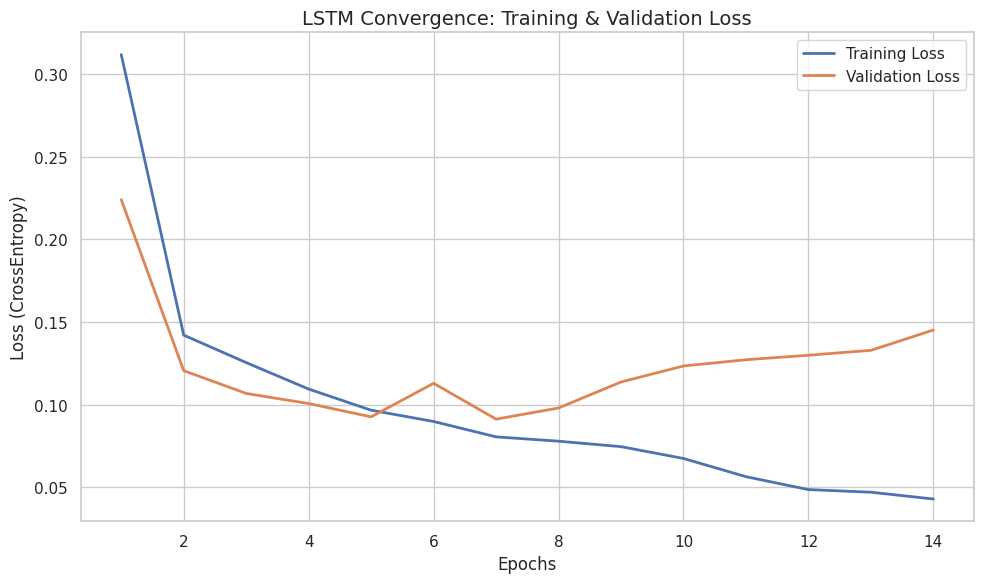

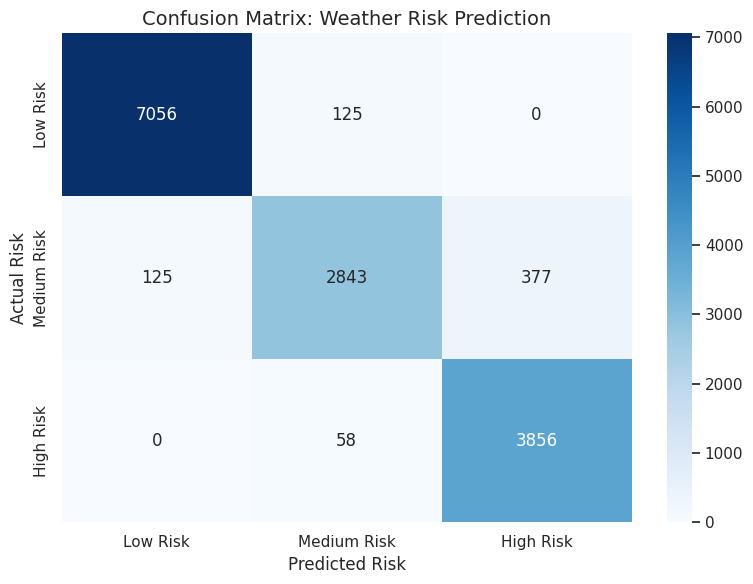

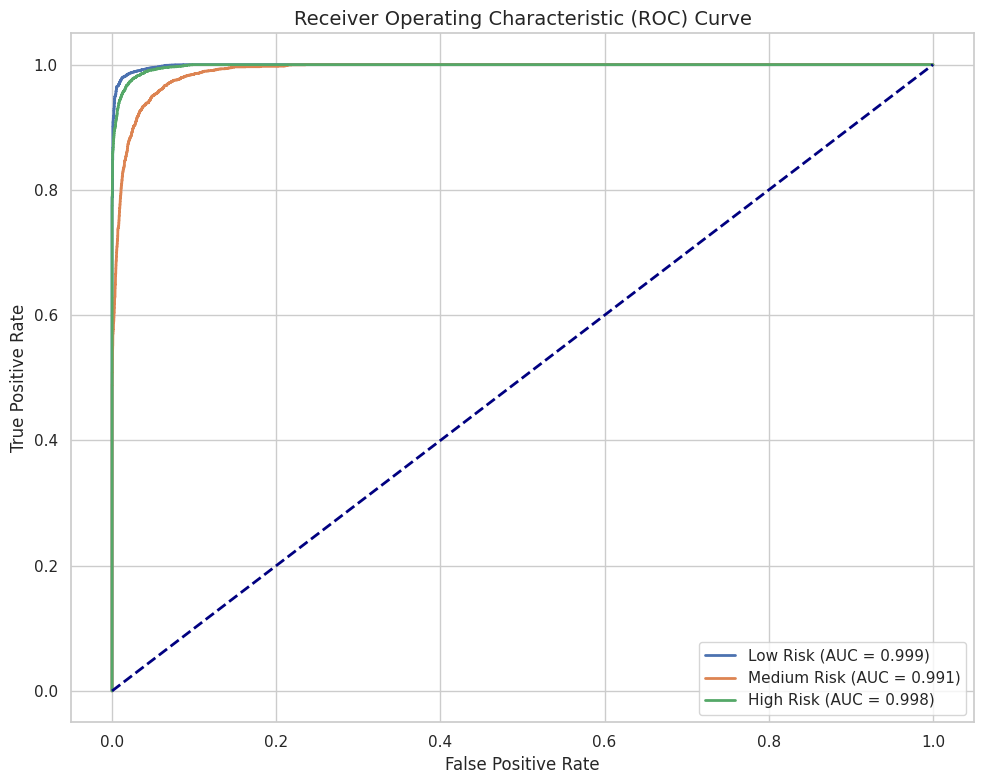

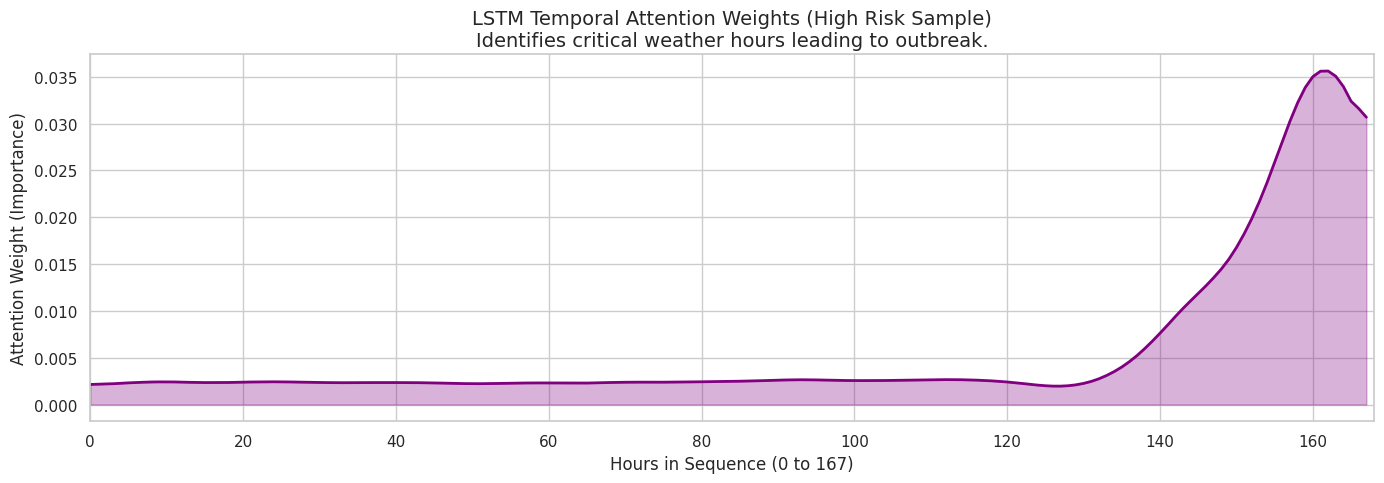

In [13]:
print("\n--- Generating Publication-Quality Figures ---")
sns.set_theme(style="whitegrid")

# 1. Training Loss Curves
epochs_range = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, history['train_loss'], label='Training Loss', lw=2)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', lw=2)
plt.title('LSTM Convergence: Training & Validation Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "loss_curves.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 2. Confusion Matrix
cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: Weather Risk Prediction', fontsize=14)
plt.ylabel('Actual Risk')
plt.xlabel('Predicted Risk')
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "confusion_matrix.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

# 3. Multi-Class ROC Curves
test_labels_bin = label_binarize(test_targets, classes=[0, 1, 2])
plt.figure(figsize=(10, 8))
for i in range(3):
    fpr, tpr, _ = roc_curve(test_labels_bin[:, i], test_probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f'{class_names[i]} (AUC = {roc_auc_score(test_labels_bin[:, i], test_probs[:, i]):.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(Config.PLOT_DIR, "roc_curve.png"), dpi=300)
plt.show(block=False)
plt.show()
plt.close()

high_risk_indices = np.where((test_targets == 2) & (test_preds == 2))[0]
if len(high_risk_indices) > 0:
    sample_idx = high_risk_indices[0]
    sample_attn = attention_matrices[sample_idx]
    
    # Smooth attention for cleaner visualization
    smoothed_attn = pd.Series(sample_attn).rolling(window=6, center=True, min_periods=1).mean().values
    
    plt.figure(figsize=(14, 5))
    plt.plot(range(Config.SEQ_LENGTH), smoothed_attn, color='purple', lw=2, fillstyle='bottom')
    plt.fill_between(range(Config.SEQ_LENGTH), smoothed_attn, color='purple', alpha=0.3)
    plt.title(f'LSTM Temporal Attention Weights (High Risk Sample)\nIdentifies critical weather hours leading to outbreak.', fontsize=14)
    plt.xlabel('Hours in Sequence (0 to 167)')
    plt.ylabel('Attention Weight (Importance)')
    plt.xlim(0, Config.SEQ_LENGTH)
    plt.tight_layout()
    plt.savefig(os.path.join(Config.PLOT_DIR, "attention_weights.png"), dpi=300)
    plt.show(block=False)
    plt.show()

    plt.close()

In [14]:
print("\n--- Saving Artifacts and Finalizing Packaging ---")

# Save Metrics
metrics_dict = {
    "Accuracy": float(acc),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1_Score": float(f1),
    "ROC_AUC": float(roc_auc),
    "Best_Hyperparameters": best_hp_config,
    "Sequence_Length": Config.SEQ_LENGTH
}

with open(os.path.join(Config.OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics_dict, f, indent=4)

with open(os.path.join(Config.OUT_DIR, "training_history.json"), "w") as f:
    json.dump(history, f, indent=4)
    
# Save Predictions subset
pred_df = pd.DataFrame({
    'Actual_Risk': test_targets[:1000],
    'Predicted_Risk': test_preds[:1000],
    'Confidence': np.max(test_probs[:1000], axis=1)
})
pred_df.to_csv(os.path.join(Config.OUT_DIR, "predictions.csv"), index=False)

# Save Scaler
import pickle
with open(os.path.join(Config.MODEL_DIR, "scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)

# Generate Text Summary
model_summary = str(final_model) + f"\n\nTotal Parameters: {sum(p.numel() for p in final_model.parameters())}"
with open(os.path.join(Config.OUT_DIR, "model_summary.txt"), "w") as f:
    f.write(model_summary)

# Zip Packaging
zip_filename = os.path.join(Config.OUT_DIR, "Phase_1_5_Release.zip")
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(Config.OUT_DIR):
        for file in files:
            if file.endswith('.zip'): continue
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, Config.OUT_DIR)
            zipf.write(file_path, arcname)

print(f"\nPhase 1.5 Execution Complete. All highly-optimized artifacts saved to {zip_filename}")


--- Saving Artifacts and Finalizing Packaging ---

Phase 1.5 Execution Complete. All highly-optimized artifacts saved to ./output/phase_1_5/Phase_1_5_Release.zip


In [15]:
import os
import zipfile

# Output directory
OUT_DIR = "./output/phase_1_5"

# Zip file path
zip_filename = os.path.join(OUT_DIR, "Phase_1_5_Release.zip")

os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(OUT_DIR):
        for file in files:
            if file.endswith(".zip"):
                continue

            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, OUT_DIR)
            zipf.write(file_path, arcname)

print("=" * 60)
print("ZIP Successfully Created!")
print(zip_filename)

print("\nContents:")
with zipfile.ZipFile(zip_filename, "r") as z:
    for f in z.namelist():
        print(" -", f)

print("=" * 60)

ZIP Successfully Created!
./output/phase_1_5/Phase_1_5_Release.zip

Contents:
 - training_history.json
 - model_summary.txt
 - predictions.csv
 - metrics.json
 - models/best_lstm_model.h5
 - models/scaler.pkl
 - plots/roc_curve.png
 - plots/attention_weights.png
 - plots/confusion_matrix.png
 - plots/loss_curves.png
